In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

In [3]:
DATA_PATH = "../data/simulation/bdt_ctmc/0/T_extant.json"

In [4]:
from simulator import load_tree

T, root = load_tree(DATA_PATH)
T

In [5]:
T.nodes(data=True)

NodeDataView({0: {'time': 0.0, 'event': 'root', 'state': 'A'}, 1: {'time': 0.08204891836733094, 'event': 'birth', 'state': 'A'}, 2: {'time': 0.12262629735275726, 'event': 'birth', 'state': 'A'}, 4: {'time': 0.1634297677205061, 'event': 'birth', 'state': 'A'}, 6: {'time': 0.3669819222880825, 'event': 'birth', 'state': 'C'}, 7: {'time': 0.42146834619020596, 'event': 'birth', 'state': 'A'}, 8: {'time': 0.1891004969785741, 'event': 'birth', 'state': 'A'}, 12: {'time': 0.5321424818632318, 'event': 'birth', 'state': 'C'}, 13: {'time': 0.3455825007348193, 'event': 'birth', 'state': 'B'}, 14: {'time': 0.40334550071848824, 'event': 'birth', 'state': 'A'}, 16: {'time': 0.351840756398576, 'event': 'birth', 'state': 'B'}, 18: {'time': 0.43613938229713306, 'event': 'birth', 'state': 'B'}, 19: {'time': 0.45011557082385384, 'event': 'birth', 'state': 'B'}, 20: {'time': 0.6385229965012624, 'event': 'birth', 'state': 'C'}, 22: {'time': 0.44075524059355786, 'event': 'birth', 'state': 'C'}, 25: {'time': 

In [6]:
T.edges(data=True)

OutEdgeDataView([(0, 1, {'start_time': 0.0, 'end_time': 0.08204891836733094, 'length': 0.08204891836733094}), (1, 2, {'start_time': 0.08204891836733094, 'end_time': 0.12262629735275726, 'length': 0.04057737898542632}), (1, 12, {'start_time': 0.08204891836733094, 'end_time': 0.5321424818632318, 'length': 0.4500935634959008}), (2, 4, {'start_time': 0.12262629735275726, 'end_time': 0.1634297677205061, 'length': 0.04080347036774884}), (2, 6, {'start_time': 0.12262629735275726, 'end_time': 0.3669819222880825, 'length': 0.24435562493532526}), (4, 7, {'start_time': 0.1634297677205061, 'end_time': 0.42146834619020596, 'length': 0.25803857846969985}), (4, 8, {'start_time': 0.1634297677205061, 'end_time': 0.1891004969785741, 'length': 0.025670729258067987}), (6, 20, {'start_time': 0.3669819222880825, 'end_time': 0.6385229965012624, 'length': 0.2715410742131799}), (6, 48, {'start_time': 0.3669819222880825, 'end_time': 0.5457453809370478, 'length': 0.1787634586489653}), (7, 25, {'start_time': 0.42

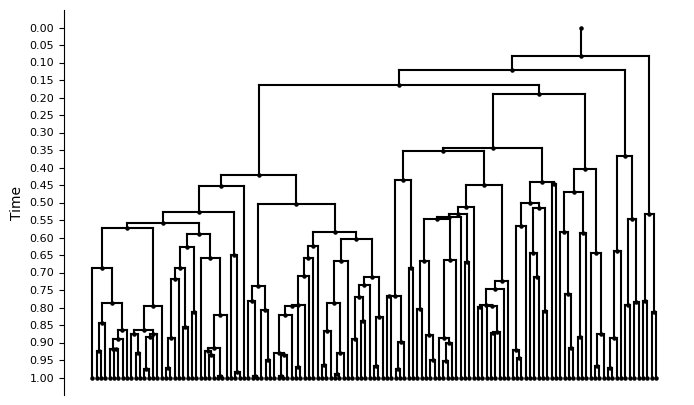

In [7]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=root, add_labels=False)

In [8]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int, {'A': 118, 'C': 75, 'B': 69})

In [37]:
from likelihood import add_node_times

T = add_node_times(T, root=root)

In [38]:
T.nodes(data=True)

NodeDataView({0: {'time': 0.0, 'event': 'root', 'state': 'A', 'T': 1}, 1: {'time': 0.08204891836733094, 'event': 'birth', 'state': 'A', 'T': 0.917951081632669}, 2: {'time': 0.12262629735275726, 'event': 'birth', 'state': 'A', 'T': 0.8773737026472428}, 4: {'time': 0.1634297677205061, 'event': 'birth', 'state': 'A', 'T': 0.8365702322794939}, 6: {'time': 0.3669819222880825, 'event': 'birth', 'state': 'C', 'T': 0.6330180777119174}, 7: {'time': 0.42146834619020596, 'event': 'birth', 'state': 'A', 'T': 0.578531653809794}, 8: {'time': 0.1891004969785741, 'event': 'birth', 'state': 'A', 'T': 0.8108995030214259}, 12: {'time': 0.5321424818632318, 'event': 'birth', 'state': 'C', 'T': 0.46785751813676824}, 13: {'time': 0.3455825007348193, 'event': 'birth', 'state': 'B', 'T': 0.6544174992651808}, 14: {'time': 0.40334550071848824, 'event': 'birth', 'state': 'A', 'T': 0.5966544992815117}, 16: {'time': 0.351840756398576, 'event': 'birth', 'state': 'B', 'T': 0.6481592436014241}, 18: {'time': 0.43613938

In [42]:
from scipy.special import logsumexp
import networkx as nx
import numpy as np
from math import log, ceil, floor


def calculate_log_likelihood_ctmc(
    T: nx.DiGraph,
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    sampling_rate: float,
    transition_probabilities: np.ndarray,
    one_by_delta_t: int = 1000,
):

    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t

    ####################################################################
    # Extinction probabilities U
    ####################################################################

    U = np.zeros((one_by_delta_t + 1, num_states))
    U[0, :] = 1.0 - sampling_rate

    for t in range(1, one_by_delta_t + 1):

        for s in range(num_states):

            U[t, s] = (
                (1.0
                 - (birth_rates[s]
                    + death_rates[s]
                    + transition_probabilities[s, :].sum())
                 * delta_t)
                * U[t - 1, s]
                + birth_rates[s]
                * delta_t
                * U[t - 1, s] ** 2
                + death_rates[s] * delta_t
                + sum(
                    transition_probabilities[s, d]
                    * delta_t
                    * U[t - 1, d]
                    for d in range(num_states)
                    if d != s
                )
            )

    ####################################################################
    # Postorder edge list
    ####################################################################

    postorder_edges = []

    for parent in nx.dfs_postorder_nodes(T):
        for child in T.successors(parent):
            postorder_edges.append((parent, child))

    edge_to_idx = {
        edge: idx
        for idx, edge in enumerate(postorder_edges)
    }
    num_edges = len(postorder_edges)

    ####################################################################
    # LL[e,s]
    # likelihood at parent end of edge
    ####################################################################

    LL = np.full((num_edges, num_states), -np.inf)

    ####################################################################
    # Process edges bottom-up
    ####################################################################

    for edge_idx, (u, v) in enumerate(postorder_edges):

        parent_time = T.nodes[u]["T"]
        child_time = T.nodes[v]["T"]

        children = list(T.successors(v))

        ###############################################################
        # likelihood at child event
        ###############################################################

        if len(children) == 0:

            child_state = ord(T.nodes[v]["state"]) - ord('A')

            initial = np.full(num_states, -np.inf)
            initial[child_state] = log(sampling_rate)

        elif len(children) == 2:

            c1, c2 = children

            LL1 = LL[edge_to_idx[(v,c1)]]
            LL2 = LL[edge_to_idx[(v,c2)]]

            if np.all(np.isneginf(LL1)):
                print("child edge not computed", (v,c1))

            if np.all(np.isneginf(LL2)):
                print("child edge not computed", (v,c2))

            initial = (
                np.log(birth_rates)
                + np.log(delta_t)
                + LL1
                + LL2
            )

        else:
            raise ValueError(
                f"Node {v} has {len(children)} children. "
                "Tree must be binary."
            )

        ###############################################################
        # discretized branch
        ###############################################################

        e_t = int(round(child_time * one_by_delta_t))
        s_t = int(round(parent_time * one_by_delta_t))

        e_t = min(max(e_t, 0), one_by_delta_t)
        s_t = min(max(s_t, 0), one_by_delta_t)

        # print(f"Processing edge {(u,v)}: child_time={child_time}, parent_time={parent_time}, e_t={e_t}, s_t={s_t}")

        previous = initial.copy()

        ###############################################################
        # propagate from child -> parent
        ###############################################################

        for t in range(e_t, s_t):

            current = np.full(num_states, -np.inf)

            total_rate = (
                birth_rates
                + death_rates
                + transition_probabilities.sum(axis=1)
            )

            A = (
                1.0
                - total_rate * delta_t
                + 2.0
                * birth_rates
                * U[t - 1, :]
                * delta_t
            )

            for s in range(num_states):

                terms = []

                if A[s] > 0:
                    terms.append(
                        np.log(A[s]) + previous[s]
                    )

                for d in range(num_states):

                    if d == s:
                        continue

                    q = transition_probabilities[s, d]

                    if q > 0:
                        terms.append(
                            np.log(q * delta_t)
                            + previous[d]
                        )

                current[s] = logsumexp(terms)

            previous = current

        LL[edge_idx] = previous

    ####################################################################
    # Root likelihood
    ####################################################################

    root = next(
        n for n in T.nodes
        if T.in_degree(n) == 0
    )

    root_children = list(T.successors(root))

    if len(root_children) != 1:
        raise ValueError(
            "Expected a dummy root with one child."
        )

    root_edge = edge_to_idx[(root, root_children[0])]

    print("LL at root edge:", root_edge, LL[root_edge])

    root_loglikelihood = LL[root_edge, 0]

    return root_loglikelihood, LL, U




calculate_log_likelihood_ctmc(
    T,
    birth_rates=np.array([7.0, 5.5, 3.5]),
    death_rates=np.array([0.1, 0.1, 0.1]),
    sampling_rate=0.5,
    transition_probabilities=np.array([
                [0.0, 1.0, 1.5],
                [0.0, 0.0, 0.8],
                [0.0, 0.0, 0.0],
    ]),
    one_by_delta_t=1000,
)

LL at root edge: 260 [-931.23437457          -inf          -inf]


(np.float64(-931.2343745680483),
 array([[-3.45101807e+00, -8.08588556e-01,            -inf],
        [-2.98339664e+00, -3.55346276e+00, -7.20324663e-01],
        [-1.13588311e+01, -9.75855686e+00,            -inf],
        [-1.35994629e+00,            -inf,            -inf],
        [-2.94194868e+00, -3.50827569e+00, -7.22498659e-01],
        [-9.83249576e-01,            -inf,            -inf],
        [-9.87643835e-01,            -inf,            -inf],
        [-8.89143764e+00,            -inf,            -inf],
        [-1.49720697e+01,            -inf,            -inf],
        [-1.11878689e+00,            -inf,            -inf],
        [-2.11877358e+01,            -inf,            -inf],
        [-1.25382101e+00,            -inf,            -inf],
        [-1.80322568e+01,            -inf,            -inf],
        [-2.78611615e+01,            -inf,            -inf],
        [-2.43840739e+00,            -inf,            -inf],
        [-5.15820902e+01,            -inf,          

In [43]:
types = ["A", "B", "C"]

transition_maps = [
    ("A", ["B", "C"]),
    ("B", ["C"]),
]

In [49]:
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

MAX_DEATH = 1.0
MAX_BIRTH = 10.0
MAX_TRANSITION = 5.0


def unpack_params(theta):

    k = 0

    ####################################################
    # death rates
    ####################################################

    death = np.zeros(len(types))

    for i in range(len(types)):
        death[i] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    ####################################################
    # birth rates
    ####################################################

    birth = np.zeros(len(types))

    for i in range(len(types)):
        birth[i] = (
            death[i]
            + (MAX_BIRTH - death[i]) * sigmoid(theta[k])
        )
        k += 1

    ####################################################
    # transition rates
    ####################################################

    Q = np.zeros((len(types), len(types)))

    type_to_idx = {
        t: i
        for i, t in enumerate(types)
    }

    for src, transition_to in transition_maps:

        i = type_to_idx[src]

        for dst in transition_to:

            j = type_to_idx[dst]

            Q[i, j] = (
                MAX_TRANSITION
                * sigmoid(theta[k])
            )

            k += 1

    return birth, death, Q


def pack_initial():

    params = []

    # death parameters
    params.extend([0.0] * len(types))

    # birth parameters
    params.extend([0.0] * len(types))

    # transition parameters
    for _, transition_to in transition_maps:
        params.extend([0.0] * len(transition_to))

    return np.array(params)


def neg_log_likelihood(theta, trees, sampling_rate=0.5):

    birth, death, Q = unpack_params(theta)

    total_nll = 0.0

    for tree in trees:

        ll, _, _ = calculate_log_likelihood_ctmc(
            T=tree,
            birth_rates=birth,
            death_rates=death,
            sampling_rate=sampling_rate,
            transition_probabilities=Q,
            one_by_delta_t=100,
        )

        total_nll -= ll

    print(
        f"NLL={total_nll:.6f}",
        f"birth={birth}",
        f"death={death}",
    )

    return total_nll


def find_params(trees, sampling_rate=0.5):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, sampling_rate),
        method="L-BFGS-B",
        options={
            "disp": True,
            "maxiter": 500,
        },
    )

    birth, death, Q = unpack_params(result.x)

    print("\nOptimization finished")
    print("Success:", result.success)
    print("Message:", result.message)
    print("Log-likelihood:", -result.fun)
    print("Birth rates:", birth)
    print("Death rates:", death)
    print("Transition rates:")
    print(Q)

    return birth, death, Q, result

In [50]:
find_params([T])

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_78717/2115526845.py:115: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = minimize(


LL at root edge: 260 [-666.45553878          -inf          -inf]
NLL=666.455539 birth=[5.25 5.25 5.25] death=[0.5 0.5 0.5]
LL at root edge: 260 [-666.45553878          -inf          -inf]
NLL=666.455539 birth=[5.25 5.25 5.25] death=[0.5 0.5 0.5]
LL at root edge: 260 [-666.45553878          -inf          -inf]
NLL=666.455539 birth=[5.25 5.25 5.25] death=[0.5 0.5 0.5]
LL at root edge: 260 [-666.45553877          -inf          -inf]
NLL=666.455539 birth=[5.25 5.25 5.25] death=[0.5 0.5 0.5]
LL at root edge: 260 [-666.45553862          -inf          -inf]
NLL=666.455539 birth=[5.25000002 5.25       5.25      ] death=[0.5 0.5 0.5]
LL at root edge: 260 [-666.45553878          -inf          -inf]
NLL=666.455539 birth=[5.25       5.25000002 5.25      ] death=[0.5 0.5 0.5]
LL at root edge: 260 [-666.45553892          -inf          -inf]
NLL=666.455539 birth=[5.25       5.25       5.25000002] death=[0.5 0.5 0.5]
LL at root edge: 260 [-666.45553888          -inf          -inf]
NLL=666.455539 birth

(array([7.36262698, 4.99146731, 2.78441719]),
 array([5.23772126e-04, 3.67697162e-08, 1.22558150e-07]),
 array([[0.        , 0.66298113, 1.67454786],
        [0.        , 0.        , 0.99250866],
        [0.        , 0.        , 0.        ]]),
   message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
   success: True
    status: 0
       fun: 633.1469389175278
         x: [-7.554e+00 -1.712e+01 -1.591e+01  1.027e+00 -3.413e-03
             -9.522e-01 -1.878e+00 -6.861e-01 -1.396e+00]
       nit: 30
       jac: [-1.137e-05  0.000e+00  1.137e-05  2.206e-03  3.138e-03
              4.275e-03 -2.615e-04  1.785e-03  4.547e-05]
      nfev: 350
      njev: 35
  hess_inv: <9x9 LbfgsInvHessProduct with dtype=float64>)

In [33]:
plot_differentiation_tree(diff_T, birth_rates, death_rates, transition_probabilities=Q)

NameError: name 'birth_rates' is not defined